# Visual Product Finder — Part 1: Dataset Exploration (EDA)

**AI-powered visual search · Computer Vision**

This project builds a **Visual Product Finder**: a user uploads an image of a fashion product (a shoe, a shirt, a bag...) and the system returns visually similar products from a catalog.

## Project roadmap

| Part | Goal |
|------|------|
| **1. Dataset exploration (this notebook)** | Understand the data, validate images, build a clean product table |
| 2. Image preprocessing | Build a reliable image-loading pipeline compatible with ResNet50 |
| 3. Feature extraction | Convert each image into an embedding vector with a pretrained ResNet50 |
| 4. Similarity search | Retrieve similar products with cosine similarity |
| 5. Evaluation | Inspect result quality and failure cases |
| 6. Deployment | Save artifacts, build a FastAPI service and a web interface |

**Dataset:** [Fashion Product Images Dataset](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-dataset) (images + `styles.csv` metadata).

> **Goal of this notebook:** know exactly what data we have, confirm that every metadata record matches a valid image, and save a clean table for the next steps. We do **not** train any model here.

## Questions this notebook answers

1. How many product records and image files do we have?
2. What does `styles.csv` contain?
3. How are product IDs mapped to image filenames?
4. Are there missing values, invalid IDs, duplicate records or corrupted images?
5. Do metadata records and image files match each other?
6. What do products from different categories look like?

## 1. Setup

We import the libraries and check the compute environment. A GPU is not needed for this notebook, but we verify it now because it will matter when we extract ResNet50 features later.

In [1]:
import os
import csv
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
Device: cuda
GPU name: Tesla T4


## 2. Loading the Dataset

We define the dataset paths in one place so they are easy to change.

In [2]:
DATASET_PATH = Path("/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset/fashion-dataset")
CSV_PATH = DATASET_PATH / "styles.csv"
IMAGE_DIR = DATASET_PATH / "images"

OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

# ---- Speed settings ----
QUICK_TEST = False  # True: check only the first 2000 images (fast sanity test)
DEEP_CHECK = False   # True: fully decode every image (slow, finds truncated files)
N_WORKERS  = 32      # threads for reading images (I/O-bound work)

print("Dataset contents:", os.listdir(DATASET_PATH))
print("CSV exists:", CSV_PATH.is_file())
print("Image folder exists:", IMAGE_DIR.is_dir())

Dataset contents: ['images.csv', 'images', 'styles.csv', 'styles']
CSV exists: True
Image folder exists: True


### Reading `styles.csv` safely

Some product names in `styles.csv` contain unquoted commas, which makes a few rows have **more fields than the header**. A plain `pd.read_csv` can fail or misalign columns on those rows.

To handle this, we read the file with Python's `csv` module. If a row has extra fields, we assume the extra commas belong to the **last column** (`productDisplayName`) and merge them back. Rows with too few fields are reported and skipped.

In [3]:
rows, skipped = [], []

with open(CSV_PATH, "r", encoding="utf-8-sig", newline="") as f:
    reader = csv.reader(f)
    columns = next(reader)

    for line_number, row in enumerate(reader, start=2):
        if len(row) > len(columns):
            row = row[:len(columns) - 1] + [",".join(row[len(columns) - 1:])]

        if len(row) < len(columns):
            skipped.append((line_number, row))
            continue

        rows.append(row)

df = pd.DataFrame(rows, columns=columns)

print("Columns:", columns)
print("Rows loaded:", len(df))
print("Rows skipped (too few fields):", len(skipped))
for line_number, row in skipped[:5]:
    print(f"  line {line_number}: {row}")

Columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']
Rows loaded: 44446
Rows skipped (too few fields): 0


## 3. Metadata Overview

Let's look at the structure of the table: column names, data types and the first rows.

In [4]:
df.head(10)

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012,Casual,Puma Men Grey T-shirt
5,1855,Men,Apparel,Topwear,Tshirts,Grey,Summer,2011,Casual,Inkfruit Mens Chain Reaction T-shirt
6,30805,Men,Apparel,Topwear,Shirts,Green,Summer,2012,Ethnic,Fabindia Men Striped Green Shirt
7,26960,Women,Apparel,Topwear,Shirts,Purple,Summer,2012,Casual,Jealous 21 Women Purple Shirt
8,29114,Men,Accessories,Socks,Socks,Navy Blue,Summer,2012,Casual,Puma Men Pack of 3 Socks
9,30039,Men,Accessories,Watches,Watches,Black,Winter,2016,Casual,Skagen Men Black Watch


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44446 entries, 0 to 44445
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  44446 non-null  object
 1   gender              44446 non-null  object
 2   masterCategory      44446 non-null  object
 3   subCategory         44446 non-null  object
 4   articleType         44446 non-null  object
 5   baseColour          44446 non-null  object
 6   season              44446 non-null  object
 7   year                44446 non-null  object
 8   usage               44446 non-null  object
 9   productDisplayName  44446 non-null  object
dtypes: object(10)
memory usage: 3.4+ MB


### Column meaning

| Column | Description |
|--------|-------------|
| `id` | Unique product identifier; also the **image filename** (`<id>.jpg`) |
| `gender` | Target group (Men, Women, Boys, Girls, Unisex) |
| `masterCategory` | Top-level category (Apparel, Footwear, Accessories...) |
| `subCategory` | Mid-level category |
| `articleType` | Specific product type (Tshirts, Casual Shoes, Watches...) |
| `baseColour` | Main colour |
| `season`, `year` | Collection season and year |
| `usage` | Intended use (Casual, Sports, Formal...) |
| `productDisplayName` | Product name shown in the store |

The category columns will not be used to train anything, but they will help us **judge retrieval quality** later.

### Converting `id` and `year` to numbers

`csv.reader` returns everything as text. We convert `id` and `year` to numeric values. With `errors="coerce"`, invalid values become `NaN` instead of crashing, so we can count and inspect them.

In [6]:
df["id"] = pd.to_numeric(df["id"], errors="coerce")
df["year"] = pd.to_numeric(df["year"], errors="coerce")

print("Invalid IDs:", df["id"].isna().sum())
print("Invalid / missing years:", df["year"].isna().sum())

Invalid IDs: 0
Invalid / missing years: 1


## 4. Data Quality Checks

### 4.1 Missing values

Missing metadata does not stop image search (we only need the image), but we should know where it exists. Empty strings are converted to `NaN` first so they are counted as missing.

In [7]:
df = df.replace(r"^\s*$", np.nan, regex=True)

missing = df.isna().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(df) * 100).round(2)
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,percent
season,21,0.05
year,1,0.00
usage,1,0.00


### 4.2 Invalid and duplicate IDs

`id` must be valid and unique, because it links each record to exactly one image. Invalid or duplicate IDs would later cause the API to return the wrong product information.

In [8]:
print("Invalid IDs:", df["id"].isna().sum())
print("Duplicate IDs:", df["id"].dropna().duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Invalid IDs: 0
Duplicate IDs: 0
Fully duplicated rows: 0


## 5. Linking Metadata to Images

Each image file is named `<id>.jpg`. We only build filenames for rows with a valid `id`, so we never create names like `<NA>.jpg`. Then we check whether each file really exists.

In [9]:
df = df[df["id"].notna()].copy()
df["id"] = df["id"].astype("int64")

df["image"] = df["id"].astype(str) + ".jpg"
df["image_path"] = df["image"].apply(lambda name: IMAGE_DIR / name)

# One directory listing is far faster than calling is_file() 44k times on a network disk
files_on_disk = {e.name for e in os.scandir(IMAGE_DIR) if e.name.endswith(".jpg")}
df["image_exists"] = df["image"].isin(files_on_disk)
df = df.reset_index(drop=True)

print("Total products:", len(df))
print("Images found:", df["image_exists"].sum())
print("Images missing:", (~df["image_exists"]).sum())

Total products: 44446
Images found: 44441
Images missing: 5


### Do the files on disk match the CSV?

The check above finds records without images. Here we also look in the opposite direction: images in the folder that have **no** metadata record.

In [10]:
files_in_csv = set(df["image"])

print("Image files on disk:", len(files_on_disk))
print("In CSV but not on disk:", len(files_in_csv - files_on_disk))
print("On disk but not in CSV:", len(files_on_disk - files_in_csv))

Image files on disk: 44441
In CSV but not on disk: 5
On disk but not in CSV: 0


### 5.1 Image integrity and sizes

A file can exist but still be unreadable. We open every image and record its size and **colour mode** (grayscale or RGBA images must be converted to RGB before ResNet50).

To keep this step fast:

* Images are read in **parallel with threads**, because the work is dominated by disk reads.
* By default we read only the **file header** (enough to detect most broken files and get the size/mode). Set `DEEP_CHECK = True` to fully decode every image, which is much slower.
* Set `QUICK_TEST = True` to run on 2000 images first. Truncated files that pass the header check will be caught later, when we load every image during feature extraction.

In [11]:
from concurrent.futures import ThreadPoolExecutor

def check_image(args):
    img_id, path = args
    try:
        with Image.open(path) as img:
            width, height, mode = img.width, img.height, img.mode   # reads only the header
            if DEEP_CHECK:
                img.load()                                           # full decode (slow)
        return ("ok", img_id, width, height, mode)
    except Exception as e:
        return ("bad", img_id, str(e))

todo = list(df.loc[df["image_exists"], ["id", "image_path"]].itertuples(index=False, name=None))
if QUICK_TEST:
    todo = todo[:20000]

with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
    results = list(tqdm(pool.map(check_image, todo), total=len(todo)))

records   = [r[1:] for r in results if r[0] == "ok"]
corrupted = [(r[1], r[2]) for r in results if r[0] == "bad"]
img_info  = pd.DataFrame(records, columns=["id", "width", "height", "mode"])

print("Images checked:", len(todo))
print("Valid images:", len(img_info))
print("Corrupted images:", len(corrupted))
print("\nColour modes:")
print(img_info["mode"].value_counts())
print("\nMost common sizes (width, height):")
print(img_info.groupby(["width", "height"]).size().sort_values(ascending=False).head(5))

  0%|          | 0/44441 [00:00<?, ?it/s]

Images checked: 44441
Valid images: 44441
Corrupted images: 0

Colour modes:
mode
RGB    44441
Name: count, dtype: int64

Most common sizes (width, height):
width  height
1080   1440      24459
1800   2400      19721
150    200         119
360    480          60
540    720          21
dtype: int64


**Why this matters:** the images do not all have to be the same size, because we will resize them in the preprocessing step. Non-RGB images, however, need an explicit `.convert("RGB")`.

## 6. Category Distribution

Next we look at how products are distributed across categories. A very imbalanced catalog affects retrieval: popular categories have many neighbours, rare ones very few.

In [12]:
for col in ["gender", "masterCategory", "subCategory", "articleType"]:
    print(f"{col}: {df[col].nunique()} unique values")

gender: 5 unique values
masterCategory: 7 unique values
subCategory: 45 unique values
articleType: 143 unique values


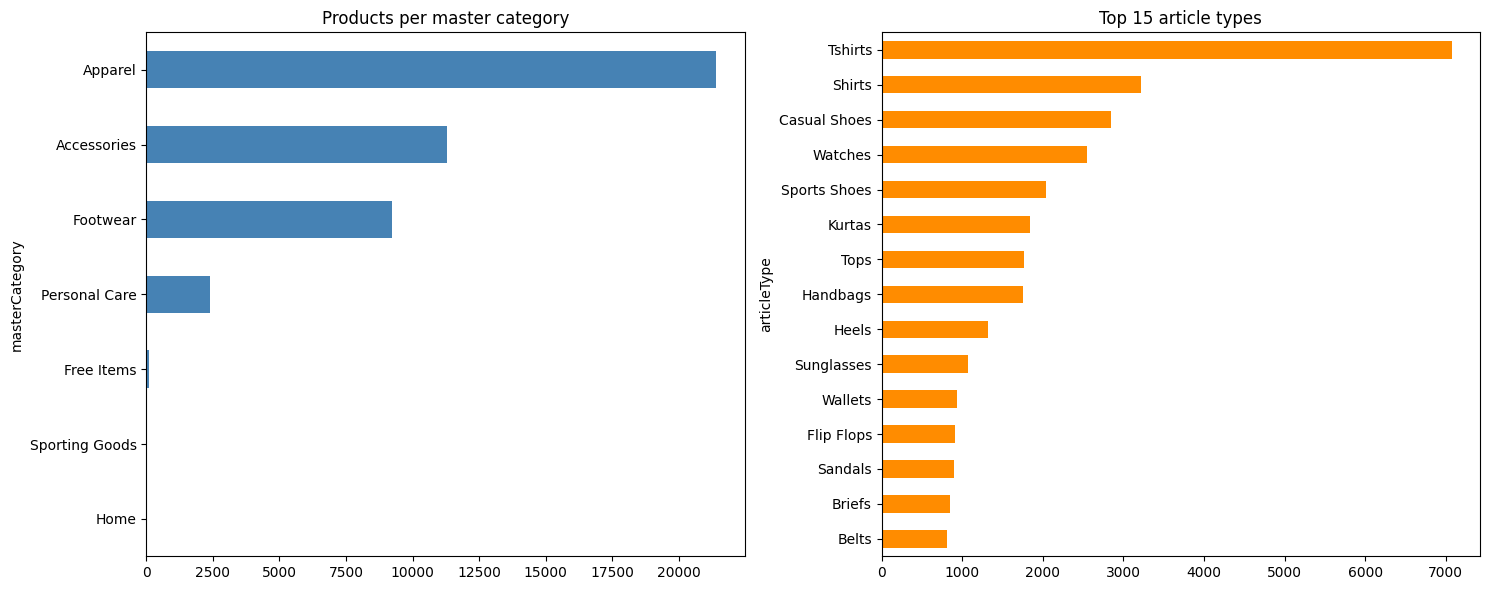

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

df["masterCategory"].value_counts().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Products per master category")

df["articleType"].value_counts().head(15).plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].invert_yaxis()
axes[1].set_title("Top 15 article types")

plt.tight_layout()
plt.show()

## 7. Visual Inspection

Numbers are not enough for an image project, so we look at real products. The first rows of a table often come from the same category, so we sample **one random product from each of the 10 most frequent article types**.

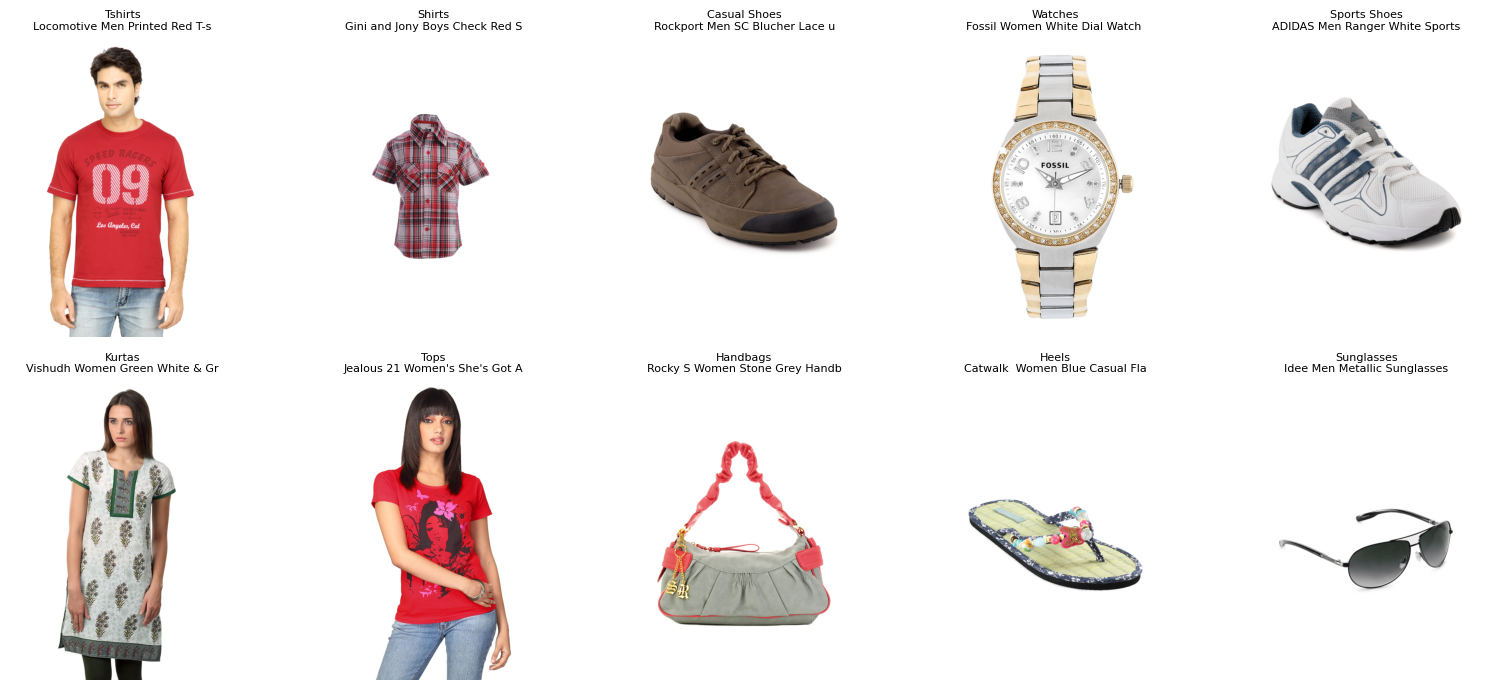

In [14]:
valid = df[df["image_exists"]]
top_types = valid["articleType"].value_counts().head(10).index

sample = pd.concat([
    valid[valid["articleType"] == t].sample(1, random_state=SEED) for t in top_types
])

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (_, row) in zip(axes.flatten(), sample.iterrows()):
    ax.imshow(mpimg.imread(row["image_path"]))
    ax.set_title(f'{row["articleType"]}\n{str(row["productDisplayName"])[:30]}', fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

We can also look at several products **inside one category** to see how much they vary visually. This is the kind of variation the model will have to handle.

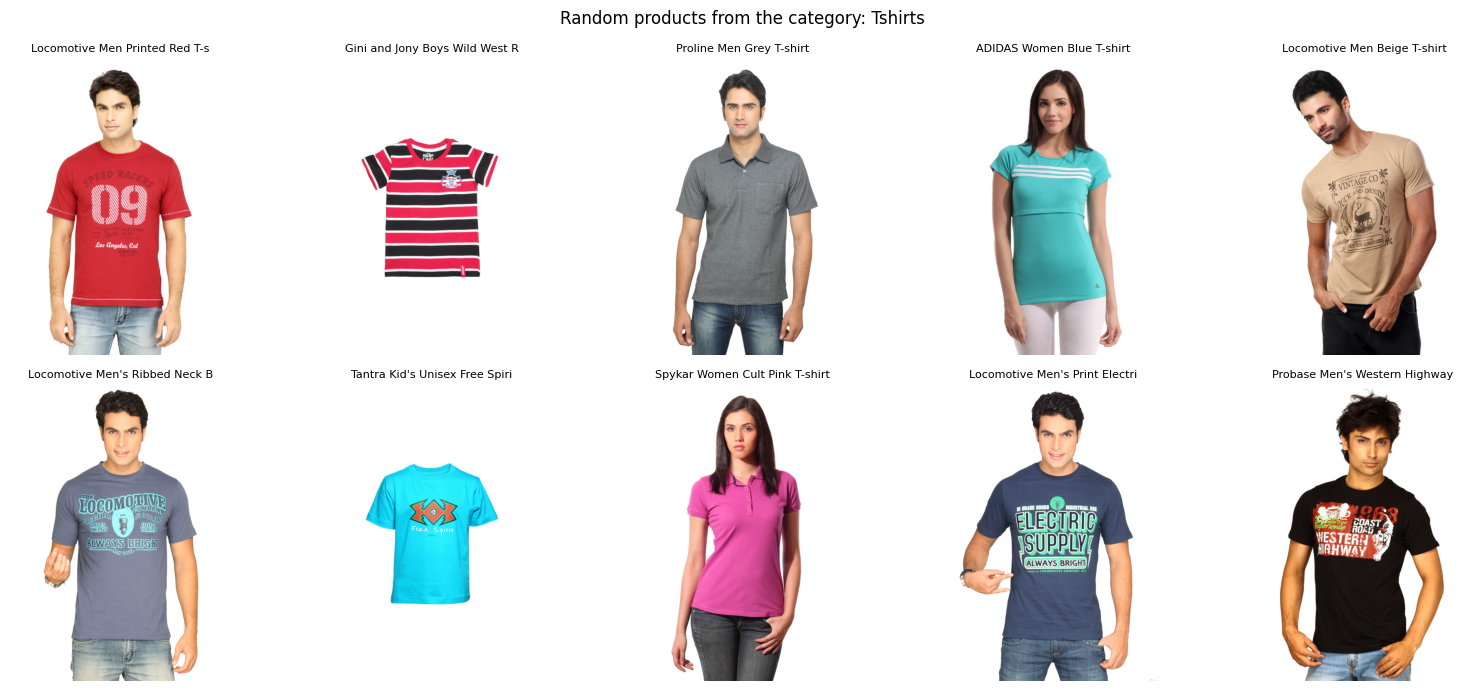

In [15]:
category = valid["articleType"].value_counts().index[0]
same_cat = valid[valid["articleType"] == category].sample(10, random_state=SEED)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (_, row) in zip(axes.flatten(), same_cat.iterrows()):
    ax.imshow(mpimg.imread(row["image_path"]))
    ax.set_title(str(row["productDisplayName"])[:30], fontsize=8)
    ax.axis("off")

plt.suptitle(f"Random products from the category: {category}", fontsize=12)
plt.tight_layout()
plt.show()

## 8. Building the Clean Product Table

We keep only products that have:

* a valid, unique `id`
* an image file that exists
* an image that opens without errors

The result is saved as `clean_products.csv` and will be the starting point of the next notebook. The `image_path` column is dropped because absolute paths change between environments; we can rebuild it from `image`.

In [16]:
assert not QUICK_TEST, "Set QUICK_TEST = False and re-run the integrity check before saving the clean table."
bad_ids = {i for i, _ in corrupted}

clean_df = (
    df[df["image_exists"] & ~df["id"].isin(bad_ids)]
    .drop_duplicates(subset="id")
    .reset_index(drop=True)
)

print("Products before cleaning:", len(df))
print("Products after cleaning:", len(clean_df))

clean_df.drop(columns=["image_path", "image_exists"]).to_csv(OUTPUT_DIR / "clean_products.csv", index=False)
print("Saved:", OUTPUT_DIR / "clean_products.csv")

Products before cleaning: 44446
Products after cleaning: 44441
Saved: /kaggle/working/clean_products.csv


## 9. Summary of Findings

> Fill in this section with the numbers from your own outputs after running the notebook.

| Item | Value |
|------|-------|
| Records in `styles.csv` | ... |
| Rows skipped (too few fields) | ... |
| Invalid / duplicate IDs | ... |
| Images found / missing | ... |
| Corrupted images | ... |
| Images not in RGB mode | ... |
| Final clean products | ... |

**Main observations**

* **Data quality:** (e.g. how many records had missing or invalid data, and which columns)
* **Category balance:** (e.g. the most frequent article types, and whether the catalog is imbalanced)
* **Image properties:** (e.g. the most common image size and any non-RGB images)

**Decisions for the next steps**

* Only products in `clean_products.csv` are used in the catalog.
* Images are converted to RGB and resized to the input size expected by ResNet50.
* Categories are used only to *evaluate* retrieval, not to build it. Matching category is a rough proxy, **not** a true measure of visual similarity.

## Next: Part 2 — Image Preprocessing

We will build a preprocessing pipeline with `torchvision.transforms` (RGB conversion, resize, tensor conversion, normalization) that matches the pretrained ResNet50 weights, and verify tensor shapes on a few images.